In [135]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix

L_list = [32, 48, 64, 80]
W_list = [4, 6, 8, 10]

J = 1
K = 2

seed = 0 


def create_random_T(Ly, K, rng):

    Tx = np.zeros((Ly, Ly), dtype=int)

    rows = np.arange(Ly)

    for k in range(K):
        Tx[(rows + k) % Ly, rows] = 1

    Tx = Tx[rng.permutation(Ly)]
    Tx = Tx[:, rng.permutation(Ly)]

    return Tx


def construct_H(L, W, J, K, seed):

    Lx = L
    Ly = L

    N = Lx * Ly

    rng = np.random.default_rng(seed)

    T = [create_random_T(Ly, K, rng) for _ in range(Lx - 1)]

    epsilon = rng.uniform(-W, W, N)

    H = lil_matrix((N, N), dtype=float)

    H.setdiag(epsilon)

    for x in range(Lx - 1):

        start1 = x * Ly
        end1 = (x + 1) * Ly

        start2 = (x + 1) * Ly
        end2 = (x + 2) * Ly

        H[start1:end1, start2:end2] = J * T[x].T

        H[start2:end2, start1:end1] = J * T[x]

    return H.tocsr(), T, epsilon

Hamiltonians = {}

for L in L_list:

    for W in W_list:

        H, T, epsilon = construct_H(L, W, J, K, seed)

        Hamiltonians[(L, W)] = H

        # print(
        #     f"L = {L:2d}, W = {W:2d}, "
        #     f"Shape = {H.shape}, "
        #     f"Non-zero elements = {H.nnz}"
        # )


print("\nAll Hamiltonians constructed successfully!")


All Hamiltonians constructed successfully!


compute the eigenvalues 

In [117]:
from scipy.sparse.linalg import eigsh
import os
import gc

# Number of eigenvalues
fraction = 32

# Directory to save results
save_dir = "Eigenvalue_Results"

os.makedirs(save_dir, exist_ok=True)


for L in L_list:

    for W in W_list:

        print(f"\nCalculating: L = {L}, W = {W}")

        # Retrieve Hamiltonian
        H = Hamiltonians[(L, W)]

        N = H.shape[0]

        num_eigenvalues = N // fraction

        print("Total sites:", N)
        print("Number of eigenvalues:", num_eigenvalues)


        eigenvalues, eigenvectors = eigsh(
            H,
            k=num_eigenvalues,
            sigma=0.0,
            which="LM"
        )


        idx = np.argsort(eigenvalues)

        eigenvalues = eigenvalues[idx]
        eigenvectors = eigenvectors[:, idx]


        filename = f"Eigen_L{L}_W{W}.npz"

        filepath = os.path.join(save_dir, filename)

        np.savez_compressed(
            filepath,
            eigenvalues=eigenvalues,
            eigenvectors=eigenvectors)

        print("Saved:", filepath)
        print("Eigenvalue shape:", eigenvalues.shape)
        print("Eigenvector shape:", eigenvectors.shape)

        # plt.figure(figsize=(6, 4))

        # plt.plot(eigenvalues, 'o-', markersize=2)

        # plt.xlabel("Eigenvalue index")
        # plt.ylabel("Energy eigenvalues")

        # plt.title(f"L = {L}, W = {W}")

        # plt.grid()
        # plt.tight_layout()

        # plt.show()
        # plt.close()

        # del eigenvalues, eigenvectors, H
        # gc.collect()

print("\nAll eigenvalue calculations completed!")


Calculating: L = 32, W = 4
Total sites: 1024
Number of eigenvalues: 32
Saved: Eigenvalue_Results/Eigen_L32_W4.npz
Eigenvalue shape: (32,)
Eigenvector shape: (1024, 32)

Calculating: L = 32, W = 6
Total sites: 1024
Number of eigenvalues: 32
Saved: Eigenvalue_Results/Eigen_L32_W6.npz
Eigenvalue shape: (32,)
Eigenvector shape: (1024, 32)

Calculating: L = 32, W = 8
Total sites: 1024
Number of eigenvalues: 32
Saved: Eigenvalue_Results/Eigen_L32_W8.npz
Eigenvalue shape: (32,)
Eigenvector shape: (1024, 32)

Calculating: L = 32, W = 10
Total sites: 1024
Number of eigenvalues: 32
Saved: Eigenvalue_Results/Eigen_L32_W10.npz
Eigenvalue shape: (32,)
Eigenvector shape: (1024, 32)

Calculating: L = 48, W = 4
Total sites: 2304
Number of eigenvalues: 72
Saved: Eigenvalue_Results/Eigen_L48_W4.npz
Eigenvalue shape: (72,)
Eigenvector shape: (2304, 72)

Calculating: L = 48, W = 6
Total sites: 2304
Number of eigenvalues: 72
Saved: Eigenvalue_Results/Eigen_L48_W6.npz
Eigenvalue shape: (72,)
Eigenvector sh

In [136]:
data = np.load("Eigenvalue_Results/Eigen_L32_W10.npz", allow_pickle=True)

eigenvalues = data['eigenvalues']
eigenvectors = data['eigenvectors']

print(eigenvectors.shape)


(1024, 32)


Level-spacing ratio

In [137]:
save_dir = "Eigenvalue_Results"

results = {}

for L in L_list:

    for W in W_list:

        filename = f"Eigen_L{L}_W{W}.npz"

        filepath = os.path.join(save_dir, filename)

        # Load eigenvalues
        data = np.load(filepath)

        eigenvalues = data["eigenvalues"]

        # Sort eigenvalues
        eigenvalues = np.sort(eigenvalues)

        # Calculate level spacings
        spacings = np.diff(eigenvalues)

        # Calculate level-spacing ratios
        r = np.minimum(spacings[:-1], spacings[1:]) / \
            np.maximum(spacings[:-1], spacings[1:])

        # Mean level-spacing ratio
        mean_r = np.mean(r)

        results[(L, W)] = mean_r

        print(f"L = {L:2d}, W = {W:2d}, <r> = {mean_r:.6f}")


all_mean_r = np.array(list(results.values()))

overall_average = np.mean(all_mean_r)

print("Overall average level-spacing ratio")

print(f"<r> average = {overall_average:.6f}")

L = 32, W =  4, <r> = 0.536715
L = 32, W =  6, <r> = 0.586099
L = 32, W =  8, <r> = 0.470663
L = 32, W = 10, <r> = 0.371290
L = 48, W =  4, <r> = 0.524325
L = 48, W =  6, <r> = 0.563528
L = 48, W =  8, <r> = 0.432360
L = 48, W = 10, <r> = 0.390386
L = 64, W =  4, <r> = 0.479623
L = 64, W =  6, <r> = 0.471898
L = 64, W =  8, <r> = 0.401132
L = 64, W = 10, <r> = 0.473738
L = 80, W =  4, <r> = 0.547241
L = 80, W =  6, <r> = 0.463648
L = 80, W =  8, <r> = 0.475636
L = 80, W = 10, <r> = 0.429467
Overall average level-spacing ratio
<r> average = 0.476109


General Inverse participation ratio

In [138]:
q_list = np.round(np.arange(0.1, 3, 0.1), 1)
# q_list = [2]

save_dir = "Eigenvalue_Results"


for L in L_list:

    for W in W_list:

        filename = f"Eigen_L{L}_W{W}.npz"
        filepath = os.path.join(save_dir, filename)

        # Load eigenvectors and eigenvalues
        data = np.load(filepath)

        eigenvalues = data["eigenvalues"]
        eigenvectors = data["eigenvectors"]

        # Probability amplitudes
        probability = np.abs(eigenvectors)**2

        # Store generalized IPR
        IPR_results = {}

        for q in q_list:

            IPR = np.sum(probability**q, axis=0)

            IPR_results[q] = IPR

        # Convert dictionary into array
        IPR_array = np.array([
            IPR_results[q] for q in q_list])

        # Save results
        IPR_filename = f"Generalized_IPR_L{L}_W{W}.npz"

        IPR_filepath = os.path.join(save_dir, IPR_filename)

        np.savez_compressed(
            IPR_filepath,
            q_list=q_list,
            IPR=IPR_array,
            eigenvalues=eigenvalues
        )

        print(
            f"L = {L:2d}, W = {W:2d}, "
            f"IPR shape = {IPR_array.shape}, "
            f"Number of q values = {len(q_list)}"
        )

print("\nAll generalized IPR calculations completed!")

L = 32, W =  4, IPR shape = (29, 32), Number of q values = 29
L = 32, W =  6, IPR shape = (29, 32), Number of q values = 29
L = 32, W =  8, IPR shape = (29, 32), Number of q values = 29
L = 32, W = 10, IPR shape = (29, 32), Number of q values = 29
L = 48, W =  4, IPR shape = (29, 72), Number of q values = 29
L = 48, W =  6, IPR shape = (29, 72), Number of q values = 29
L = 48, W =  8, IPR shape = (29, 72), Number of q values = 29
L = 48, W = 10, IPR shape = (29, 72), Number of q values = 29
L = 64, W =  4, IPR shape = (29, 128), Number of q values = 29
L = 64, W =  6, IPR shape = (29, 128), Number of q values = 29
L = 64, W =  8, IPR shape = (29, 128), Number of q values = 29
L = 64, W = 10, IPR shape = (29, 128), Number of q values = 29
L = 80, W =  4, IPR shape = (29, 200), Number of q values = 29
L = 80, W =  6, IPR shape = (29, 200), Number of q values = 29
L = 80, W =  8, IPR shape = (29, 200), Number of q values = 29
L = 80, W = 10, IPR shape = (29, 200), Number of q values = 29


In [139]:
data = np.load(
    "Eigenvalue_Results/Generalized_IPR_L64_W10.npz"
)

q_list = data["q_list"]
IPR = data["IPR"]
eigenvalues = data["eigenvalues"]

print("q values:", q_list)
print("IPR shape:", IPR.shape)

q values: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8
 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
IPR shape: (29, 128)


In [140]:
IPR.mean(axis=1)[19]

np.float64(0.23116603728333496)

General layer IPR

In [141]:
save_dir = "Eigenvalue_Results"


for L in L_list:

    for W in W_list:

        print(f"\nCalculating L = {L}, W = {W}")

        Lx = L
        Ly = L

        filename = f"Eigen_L{L}_W{W}.npz"

        filepath = os.path.join(save_dir, filename)

        data = np.load(filepath)

        eigenvalues = data["eigenvalues"]
        eigenvectors = data["eigenvectors"]

        N = Lx * Ly
        num_eigenvalues = len(eigenvalues)

        psi = eigenvectors.reshape(Lx, Ly, num_eigenvalues)

        # Probability at each site
        probability = np.abs(psi)**2


        # Sum over all sites within each layer

        layer_probability = np.sum(probability, axis=1)

        # Shape: (Lx, num_eigenvalues)

        # Shape: (len(q_list), num_eigenvalues)

        Layer_IPR = np.zeros(
            (len(q_list), num_eigenvalues))

        for i, q in enumerate(q_list):

            Layer_IPR[i] = np.sum(
                layer_probability**q,
                axis=0)

        output_filename = f"Layer_IPR_L{L}_W{W}.npz"

        output_filepath = os.path.join(
            save_dir, output_filename)

        np.savez_compressed(

            output_filepath,

            q_list=q_list,

            eigenvalues=eigenvalues,

            layer_probability=layer_probability,

            Layer_IPR=Layer_IPR)


        print("Layer probability shape:", layer_probability.shape)

        print("Layer IPR shape:", Layer_IPR.shape)

        print("Normalization check:",
              np.max(np.abs(np.sum(layer_probability, axis=0) - 1)))

        print("Saved:", output_filepath)


print("\nAll Layer IPR calculations completed!")


Calculating L = 32, W = 4
Layer probability shape: (32, 32)
Layer IPR shape: (29, 32)
Normalization check: 2.886579864025407e-15
Saved: Eigenvalue_Results/Layer_IPR_L32_W4.npz

Calculating L = 32, W = 6
Layer probability shape: (32, 32)
Layer IPR shape: (29, 32)
Normalization check: 3.1086244689504383e-15
Saved: Eigenvalue_Results/Layer_IPR_L32_W6.npz

Calculating L = 32, W = 8
Layer probability shape: (32, 32)
Layer IPR shape: (29, 32)
Normalization check: 2.220446049250313e-15
Saved: Eigenvalue_Results/Layer_IPR_L32_W8.npz

Calculating L = 32, W = 10
Layer probability shape: (32, 32)
Layer IPR shape: (29, 32)
Normalization check: 2.220446049250313e-15
Saved: Eigenvalue_Results/Layer_IPR_L32_W10.npz

Calculating L = 48, W = 4
Layer probability shape: (48, 72)
Layer IPR shape: (29, 72)
Normalization check: 5.551115123125783e-15
Saved: Eigenvalue_Results/Layer_IPR_L48_W4.npz

Calculating L = 48, W = 6
Layer probability shape: (48, 72)
Layer IPR shape: (29, 72)
Normalization check: 3.10

In [142]:
data = np.load("Eigenvalue_Results/Layer_IPR_L64_W10.npz")

q_list = data["q_list"]

eigenvalues = data["eigenvalues"]

layer_probability = data["layer_probability"]

Layer_IPR = data["Layer_IPR"]

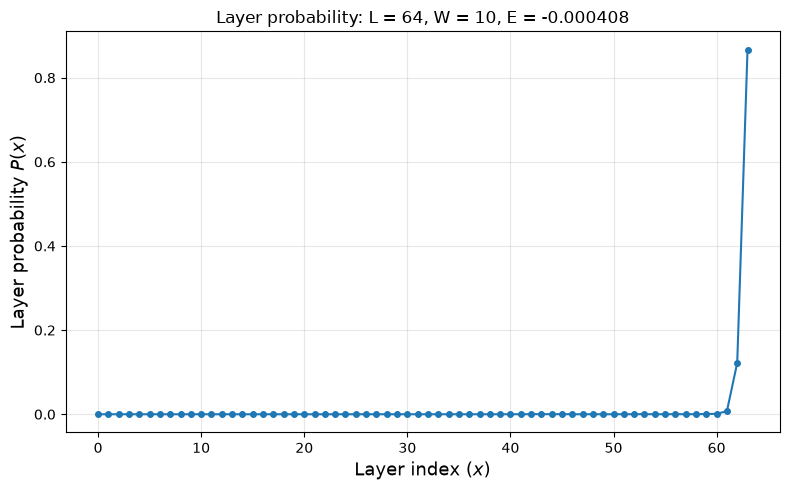

Eigenvalue closest to zero: -0.000408006747616992
Eigenstate index: 68
Total layer probability: 1.000000000000001


In [143]:
import numpy as np
import matplotlib.pyplot as plt

# Find the eigenstate closest to zero energy
idx = np.argmin(np.abs(eigenvalues))

# Extract its eigenvalue
E0 = eigenvalues[idx]

# Extract layer probability
P0 = layer_probability[:, idx]

# Layer indices
layers = np.arange(len(P0))

# Plot
plt.figure(figsize=(8, 5))

plt.plot(layers, P0, 'o-', markersize=4)

plt.xlabel("Layer index ($x$)", fontsize=13)
plt.ylabel(r"Layer probability $P(x)$", fontsize=13)

plt.title(
    f"Layer probability: L = 64, W = 10, E = {E0:.6f}"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Eigenvalue closest to zero:", E0)
print("Eigenstate index:", idx)
print("Total layer probability:", np.sum(P0))

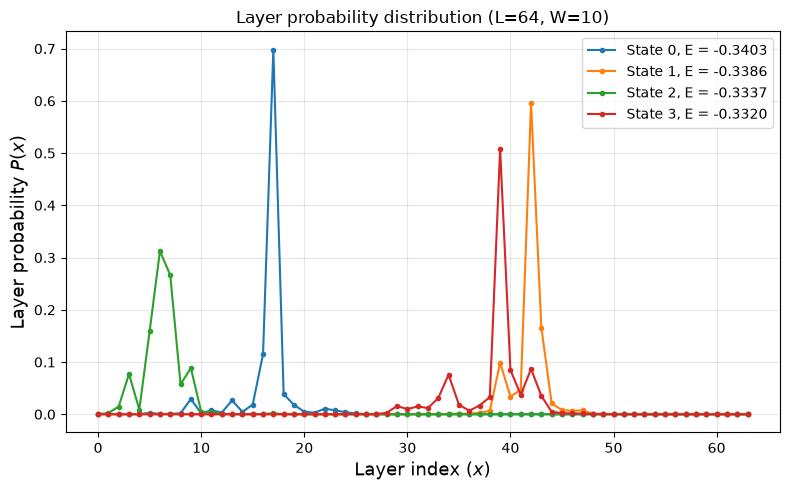

In [144]:
# States to plot
states = [0, 1, 2, 3]

layers = np.arange(layer_probability.shape[0])

plt.figure(figsize=(8, 5))

for state in states:

    P = layer_probability[:, state]

    plt.plot(
        layers,
        P,
        'o-',
        markersize=3,
        label=f"State {state}, E = {eigenvalues[state]:.4f}"
    )

plt.xlabel("Layer index ($x$)", fontsize=13)
plt.ylabel("Layer probability $P(x)$", fontsize=13)

plt.title("Layer probability distribution (L=64, W=10)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Average correlation function 

In [145]:
C_results = {}

for L in L_list:

    Lx = Ly = L

    for W in W_list:

        filename = f"Eigenvalue_Results/Layer_IPR_L{L}_W{W}.npz"

        data = np.load(filename)

        layer_probability = data["layer_probability"]

        # Shape: (Lx, number of eigenstates)
        num_states = layer_probability.shape[1]

        C = np.zeros(Lx)

        for r in range(Lx):

            C_n = np.sum(
                layer_probability[:Lx-r, :]
                * layer_probability[r:, :],
                axis=0)

            C_n /= (Lx * Ly**2)

            # Eigenstate average
            C[r] = np.mean(C_n)

        C_results[(L, W)] = C

        print(f"Completed L={L}, W={W}")




Completed L=32, W=4
Completed L=32, W=6
Completed L=32, W=8
Completed L=32, W=10
Completed L=48, W=4
Completed L=48, W=6
Completed L=48, W=8
Completed L=48, W=10
Completed L=64, W=4
Completed L=64, W=6
Completed L=64, W=8
Completed L=64, W=10
Completed L=80, W=4
Completed L=80, W=6
Completed L=80, W=8
Completed L=80, W=10


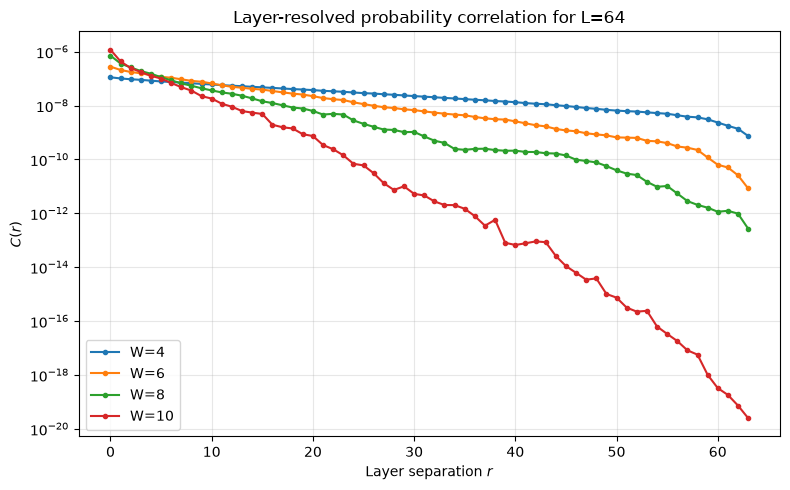

In [146]:
plt.figure(figsize=(8, 5))

for W in W_list:

    C = C_results[(64, W)]

    plt.plot(np.arange(64), C, marker='o', markersize=3, label=f"W={W}")

plt.xlabel("Layer separation $r$")
plt.ylabel(r"$C(r)$")
plt.title("Layer-resolved probability correlation for L=64")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

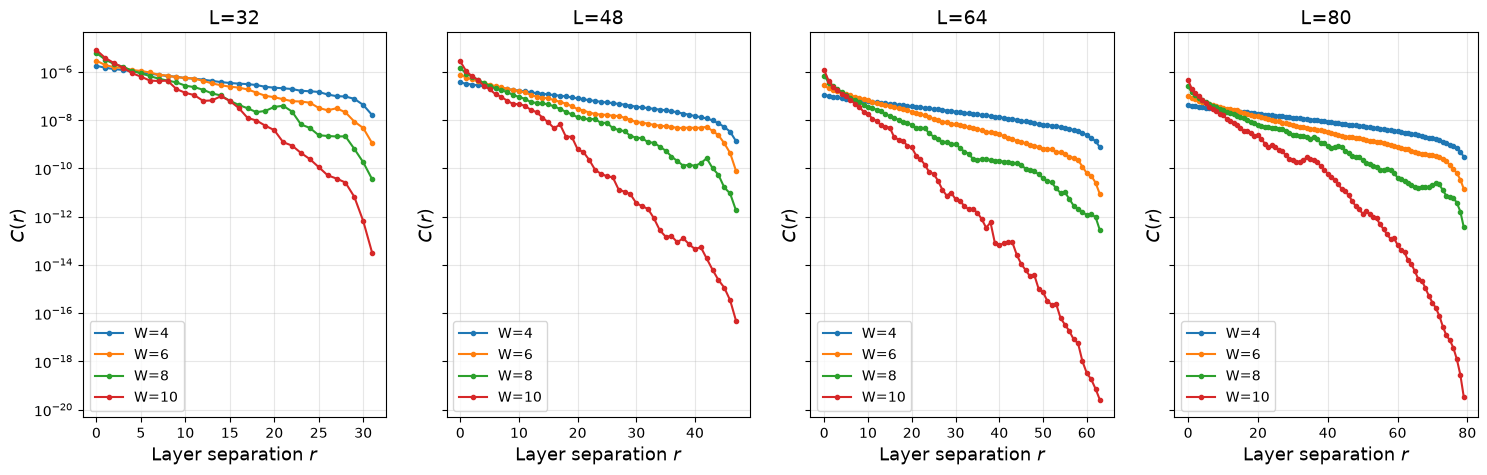

In [152]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)
# fig, axes = plt.subplots(2, 2)#, figsize=(18, 5), sharey=True)

for L in L_list:

    ax = axes[L_list.index(L)]

    for W in W_list:

        C = C_results[(L, W)]

        ax.plot(np.arange(L), C, marker='o', markersize=3, label=f"W={W}")

    ax.set_xlabel("Layer separation $r$", fontsize=13)
    ax.set_ylabel(r"$C(r)$", fontsize=13)
    ax.set_title(f"L={L}", fontsize=14)
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

Typical correlation function 

In [153]:
C_typ_results = {}

for L in L_list:

    Lx = Ly = L

    for W in W_list:

        filename = f"Eigenvalue_Results/Layer_IPR_L{L}_W{W}.npz"

        data = np.load(filename)

        layer_probability = data["layer_probability"]

        # Shape: (Lx, number of eigenstates)
        num_states = layer_probability.shape[1]

        C_typ = np.zeros(Lx)

        for r in range(Lx):

            # Calculate C_n(r) for all eigenstates
            C_n = np.sum(
                layer_probability[:Lx-r, :]
                * layer_probability[r:, :],
                axis=0
            ) / (Lx * Ly**2)

            # Typical correlation: geometric mean
            positive = C_n > 0

            if np.all(positive):
                C_typ[r] = np.exp(np.mean(np.log(C_n)))
            else:
                C_typ[r] = 0.0

        C_typ_results[(L, W)] = C_typ

        print(f"Completed L={L}, W={W}")


Completed L=32, W=4
Completed L=32, W=6
Completed L=32, W=8
Completed L=32, W=10
Completed L=48, W=4
Completed L=48, W=6
Completed L=48, W=8
Completed L=48, W=10
Completed L=64, W=4
Completed L=64, W=6
Completed L=64, W=8
Completed L=64, W=10
Completed L=80, W=4
Completed L=80, W=6
Completed L=80, W=8
Completed L=80, W=10


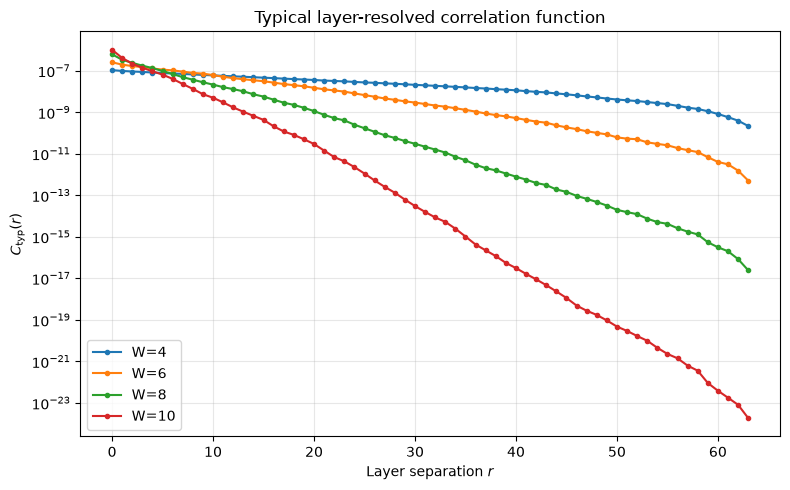

In [154]:
plt.figure(figsize=(8, 5))

for W in W_list:

    C_typ = C_typ_results[(64, W)]

    plt.plot(
        np.arange(64),
        C_typ,
        marker='o',
        markersize=3,
        label=f"W={W}"
    )

plt.xlabel("Layer separation $r$")
plt.ylabel(r"$C_{\mathrm{typ}}(r)$")
plt.title("Typical layer-resolved correlation function")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

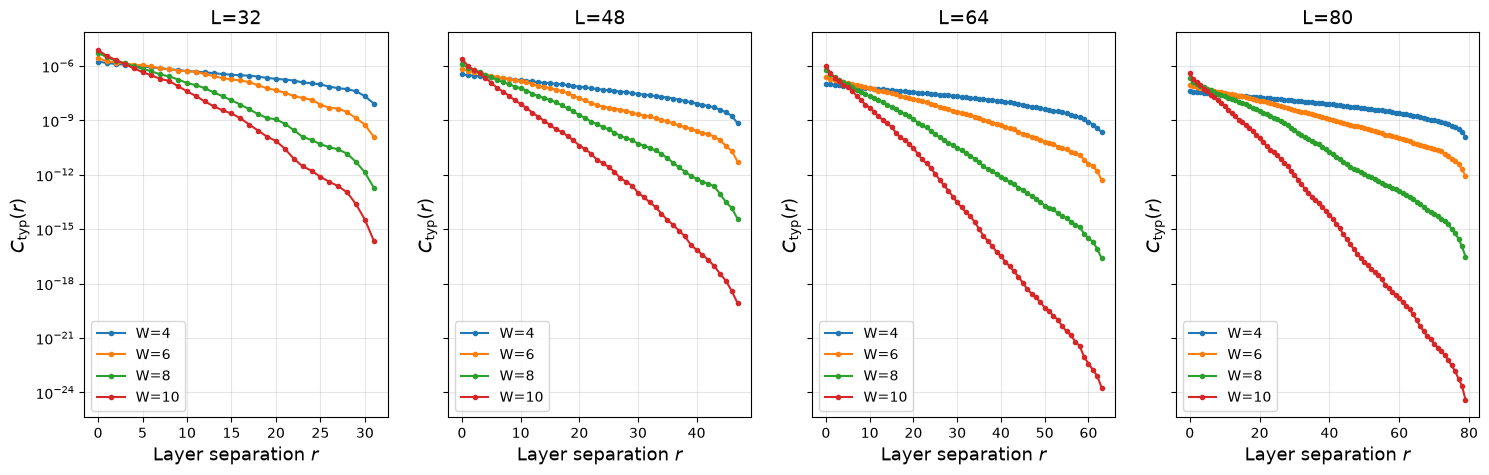

In [155]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)

for L in L_list:
    
    ax = axes[L_list.index(L)]

    for W in W_list:

        C_typ = C_typ_results[(L, W)]

        ax.plot(
            np.arange(L),
            C_typ,
            marker='o',
            markersize=3,
            label=f"W={W}"
        )

    ax.set_xlabel("Layer separation $r$", fontsize=13)
    ax.set_ylabel(r"$C_{\mathrm{typ}}(r)$", fontsize=13)
    ax.set_title(f"L={L}", fontsize=14)
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

# ----------------- seed realization ----------------------

In [280]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import lil_matrix
from scipy.sparse.linalg import eigsh

import os
import gc

L_list = [32, 48, 64, 80]
W_list = [4, 6, 8, 10]

J = 1
K = 2

fraction = 32

base_seed = 0

# Number of disorder realizations
realizations = {
    32: 50,
    48: 50,
    64: 20,
    80: 20
}

# Generalized IPR q values
q_list = np.round(np.arange(0.1, 3.0, 0.1), 1)

# Directories
save_dir = "Disorder_Averaged_Results"

os.makedirs(save_dir, exist_ok=True)

Construct the Hamiltonian 

In [281]:
def create_random_T(Ly, K, rng):

    Tx = np.zeros((Ly, Ly), dtype=int)

    rows = np.arange(Ly)

    for k in range(K):

        Tx[(rows + k) % Ly, rows] = 1

    Tx = Tx[rng.permutation(Ly)]

    Tx = Tx[:, rng.permutation(Ly)]

    return Tx


def construct_H(L, W, J, K, rng):

    Lx = L
    Ly = L

    N = Lx * Ly

    # Generate random inter-layer connections
    T = [create_random_T(Ly, K, rng) for _ in range(Lx - 1)]

    # Onsite disorder
    epsilon = rng.uniform(-W, W, N)

    H = lil_matrix((N, N), dtype=float)

    H.setdiag(epsilon)

    # Connect neighboring layers
    for x in range(Lx - 1):

        start1 = x * Ly
        end1 = (x + 1) * Ly

        start2 = (x + 1) * Ly
        end2 = (x + 2) * Ly

        H[start1:end1, start2:end2] = J * T[x].T

        H[start2:end2, start1:end1] = J * T[x]

    return H.tocsr()

Function to calculate all observables 

In [ ]:
def calculate_observables(eigenvalues, eigenvectors, L, q_list):

    Lx = L
    Ly = L

    N = Lx * Ly

    num_states = len(eigenvalues)

    # Site probability
    probability = np.abs(eigenvectors)**2

    # Generalized site IPR
    IPR = np.zeros((len(q_list), num_states))

    for i, q in enumerate(q_list):
        IPR[i] = np.sum(probability**q, axis=0)

    # Layer probability
    psi = eigenvectors.reshape(Lx, Ly, num_states)

    layer_probability = np.sum(np.abs(psi)**2, axis=1)

    # Shape: (Lx, num_states)
    # Generalized layer IPR
    Layer_IPR = np.zeros((len(q_list), num_states))

    for i, q in enumerate(q_list):
        Layer_IPR[i] = np.sum(layer_probability**q, axis=0)

    # Level-spacing ratios
    spacings = np.diff(eigenvalues)

    denominator = np.maximum(spacings[:-1], spacings[1:])

    numerator = np.minimum(spacings[:-1], spacings[1:])

    r_values = np.divide(numerator, denominator)#, out=np.zeros_like(numerator), where=denominator > 0)

    # Layer correlation for every eigenstate
    C_n_all = np.zeros((Lx, num_states))

    for r in range(Lx):

        C_n = np.sum(layer_probability[:Lx-r, :] * layer_probability[r:, :], axis=0)

        C_n /= (Lx * Ly**2)

        C_n_all[r, :] = C_n

    return (IPR, layer_probability, Layer_IPR, r_values, C_n_all)

Run all disorder realizations 

In [ ]:
for L in L_list:

    Lx = Ly = L

    num_realizations = realizations[L]

    N = Lx * Ly

    num_eigenvalues = N // fraction

    for W in W_list:
        print(f"Starting calculation: L={L}, W={W}")
        print("Number of realizations:", num_realizations)
        print("Number of eigenstates:", num_eigenvalues)

        output_file = os.path.join(save_dir, f"Raw_Results_L{L}_W{W}.npz")

        # Initialize storage arrays
        eigenvalues_all = np.zeros((num_realizations, num_eigenvalues))

        r_sum_all = np.zeros(num_realizations)
        r_count_all = np.zeros(num_realizations, dtype=int)

        IPR_sum_all = np.zeros((num_realizations, len(q_list)))

        Layer_IPR_sum_all = np.zeros((num_realizations, len(q_list)))

        layer_probability_sum_all = np.zeros((num_realizations, Lx))

        sum_C_all = np.zeros((num_realizations, Lx))

        sum_log_C_all = np.zeros((num_realizations, Lx))

        zero_count_all = np.zeros((num_realizations, Lx), dtype=int)

        completed = np.zeros(num_realizations, dtype=bool)

        
        # Resume if a previous checkpoint exists
        if os.path.exists(output_file):

            old_data = np.load(output_file)

            eigenvalues_all = old_data["eigenvalues_all"]
            r_sum_all = old_data["r_sum_all"]
            r_count_all = old_data["r_count_all"]

            IPR_sum_all = old_data["IPR_sum_all"]
            Layer_IPR_sum_all = old_data["Layer_IPR_sum_all"]

            layer_probability_sum_all = old_data["layer_probability_sum_all"]

            sum_C_all = old_data["sum_C_all"]
            sum_log_C_all = old_data["sum_log_C_all"]
            zero_count_all = old_data["zero_count_all"]

            completed = old_data["completed"]

            print("Resuming calculation. Completed:", np.sum(completed), "/", num_realizations)
            old_data.close()

        # Loop over disorder realizations
        for realization in range(num_realizations):

            if completed[realization]:
                continue

            print(f"\nL={L}, W={W}, "f"Realization {realization + 1}/{num_realizations}")

            # Independent reproducible seed
            rng = np.random.default_rng(np.random.SeedSequence([base_seed, L, W, realization]))

            # Construct Hamiltonian
            H = construct_H(L, W, J, K, rng)

            # Calculate eigenvalues and eigenvectors
            eigenvalues, eigenvectors = eigsh(H, k=num_eigenvalues, sigma=0.0, which="LM")

            # Sort eigenvalues
            idx = np.argsort(eigenvalues)

            eigenvalues = eigenvalues[idx]
            eigenvectors = eigenvectors[:, idx]

            # Calculate all observables
            (IPR, layer_probability, Layer_IPR, r_values, C_n_all) = calculate_observables(eigenvalues, eigenvectors, L, q_list)

            
            # Store eigenvalues
            eigenvalues_all[realization] = eigenvalues

            # Store level-spacing statistics
            r_sum_all[realization] = np.sum(r_values)

            r_count_all[realization] = len(r_values)

            # Store generalized site IPR
            IPR_sum_all[realization] = np.sum(IPR, axis=1)

            
            # Store generalized layer IPR
            Layer_IPR_sum_all[realization] = np.sum(Layer_IPR, axis=1)

            
            # Store layer probability
            layer_probability_sum_all[realization] = np.sum(layer_probability, axis=1)

            
            # Store arithmetic correlation sums
            sum_C_all[realization] = np.sum(C_n_all, axis=1)

            
            # Store logarithmic correlation sums
            positive = C_n_all > 0
            sum_log_C_all[realization] = np.sum(np.log(np.maximum(C_n_all, np.finfo(float).tiny)), axis=1)

            zero_count_all[realization] = np.sum(~positive, axis=1)

            # Mark realization as completed
            completed[realization] = True

            # Save checkpoint after every realization
            np.savez_compressed(
                output_file,

                eigenvalues_all=eigenvalues_all,

                r_sum_all=r_sum_all,
                r_count_all=r_count_all,

                q_list=q_list,

                IPR_sum_all=IPR_sum_all,
                Layer_IPR_sum_all=Layer_IPR_sum_all,

                layer_probability_sum_all=layer_probability_sum_all,

                sum_C_all=sum_C_all,
                sum_log_C_all=sum_log_C_all,
                zero_count_all=zero_count_all,

                completed=completed
            )

            print("Eigenvalue range:", eigenvalues[0], eigenvalues[-1])

            print("Mean level-spacing ratio:", np.mean(r_values))

            print("Maximum normalization error:", np.max(np.abs(np.sum(layer_probability, axis=0) - 1)))

            print("Realization saved.")

            # Release memory
            del H
            del eigenvalues, eigenvectors
            del IPR, layer_probability, Layer_IPR
            del r_values, C_n_all

            gc.collect()

        print(f"\nCompleted L={L}, W={W}")
        print("Saved:", output_file)

print("\nAll calculations completed!")

Starting calculation: L=32, W=4
Number of realizations: 50
Number of eigenstates: 32

L=32, W=4, Realization 1/50
Eigenvalue range: -0.16157235429314826 0.1638627945108085
Mean level-spacing ratio: 0.5459915069693768
Maximum normalization error: 3.552713678800501e-15
Realization saved.

L=32, W=4, Realization 2/50
Eigenvalue range: -0.14334008169447465 0.15113221758505604
Mean level-spacing ratio: 0.5224236144920718
Maximum normalization error: 3.552713678800501e-15
Realization saved.

L=32, W=4, Realization 3/50
Eigenvalue range: -0.1591317142318135 0.1559457527080243
Mean level-spacing ratio: 0.5026986609347023
Maximum normalization error: 3.552713678800501e-15
Realization saved.

L=32, W=4, Realization 4/50
Eigenvalue range: -0.1653529975323957 0.15940391777051086
Mean level-spacing ratio: 0.4917763001741468
Maximum normalization error: 3.552713678800501e-15
Realization saved.

L=32, W=4, Realization 5/50
Eigenvalue range: -0.16060880978094536 0.16187041065714644
Mean level-spacing 

Average all observations over disorder realizations

In [ ]:
average_dir = os.path.join(save_dir, "Averaged")
os.makedirs(average_dir, exist_ok=True)

# Final results dictionaries
eigenvalue_avg_results = {}

level_spacing_results = {}

IPR_avg_results = {}
Layer_IPR_avg_results = {}

layer_probability_avg_results = {}

C_avg_results = {}
C_typ_results = {}


for L in L_list:

    Lx = Ly = L

    for W in W_list:

        print(f"\nAveraging L={L}, W={W}")

        raw_file = os.path.join(save_dir, f"Raw_Results_L{L}_W{W}.npz")

        data = np.load(raw_file)

        completed = data["completed"]

        if not np.all(completed):

            print(
                f"Skipping L={L}, W={W}: "
                "some realizations are incomplete.")

            data.close()
            continue

        eigenvalues_all = data["eigenvalues_all"]

        r_sum_all = data["r_sum_all"]
        r_count_all = data["r_count_all"]

        IPR_sum_all = data["IPR_sum_all"]
        Layer_IPR_sum_all = data["Layer_IPR_sum_all"]

        layer_probability_sum_all = data["layer_probability_sum_all"]

        sum_C_all = data["sum_C_all"]
        sum_log_C_all = data["sum_log_C_all"]
        zero_count_all = data["zero_count_all"]

        data.close()
        
        # Total number of eigenstates
        num_realizations = len(completed)

        num_states = eigenvalues_all.shape[1]

        total_states = num_realizations * num_states

        
        # Average eigenvalue spectrum
        eigenvalue_avg = np.mean(eigenvalues_all, axis=0)

        eigenvalue_avg_results[(L, W)] = eigenvalue_avg

        # Average level-spacing ratio
        total_r_sum = np.sum(r_sum_all)

        total_r_count = np.sum(r_count_all)

        mean_r = total_r_sum / total_r_count

        level_spacing_results[(L, W)] = mean_r

        # Average generalized site IPR
        IPR_avg = np.sum(IPR_sum_all, axis=0) / total_states
        IPR_avg_results[(L, W)] = IPR_avg

        # Average generalized layer IPR
        Layer_IPR_avg = np.sum(Layer_IPR_sum_all, axis=0) / total_states

        Layer_IPR_avg_results[(L, W)] = Layer_IPR_avg

        # Average layer probability
        layer_probability_avg = np.sum(layer_probability_sum_all, axis=0) / total_states

        layer_probability_avg_results[(L, W)] = (layer_probability_avg)

        # Average correlation
        C_avg = np.sum(sum_C_all, axis=0) / total_states

        C_avg_results[(L, W)] = C_avg

        # Typical correlation
        total_log_C = np.sum(sum_log_C_all, axis=0)

        total_zero_count = np.sum(zero_count_all, axis=0)

        C_typ = np.exp(total_log_C / total_states)

        # A zero in any sample makes the exact geometric
        # average zero.
        C_typ[total_zero_count > 0] = 0.0

        C_typ_results[(L, W)] = C_typ

        # Save all averaged quantities
        average_file = os.path.join(average_dir, f"Averaged_Results_L{L}_W{W}.npz")

        np.savez_compressed(
            average_file,

            L=L,
            W=W,

            q_list=q_list,

            eigenvalue_avg=eigenvalue_avg,

            mean_r=mean_r,

            IPR_avg=IPR_avg,

            Layer_IPR_avg=Layer_IPR_avg,

            layer_probability_avg=layer_probability_avg,

            C_avg=C_avg,

            C_typ=C_typ,

            num_realizations=num_realizations,

            num_states_per_realization=num_states,

            total_states=total_states
        )

        print("Mean level-spacing ratio =", mean_r)
        print("Average eigenvalue spectrum shape =", eigenvalue_avg.shape)
        print("Average IPR shape =", IPR_avg.shape)
        print("Average Layer IPR shape =", Layer_IPR_avg.shape)
        print("Average layer probability shape =", layer_probability_avg.shape)
        print("Average correlation shape =", C_avg.shape)
        print("Typical correlation shape =", C_typ.shape)

        print("Saved:", average_file)

print("\nAll disorder averages completed!")


Averaging L=32, W=4
Mean level-spacing ratio = 0.5202072373320792
Average eigenvalue spectrum shape = (32,)
Average IPR shape = (29,)
Average Layer IPR shape = (29,)
Average layer probability shape = (32,)
Average correlation shape = (32,)
Typical correlation shape = (32,)
Saved: Disorder_Averaged_Results/Averaged/Averaged_Results_L32_W4.npz

Averaging L=32, W=6
Mean level-spacing ratio = 0.46944963020738606
Average eigenvalue spectrum shape = (32,)
Average IPR shape = (29,)
Average Layer IPR shape = (29,)
Average layer probability shape = (32,)
Average correlation shape = (32,)
Typical correlation shape = (32,)
Saved: Disorder_Averaged_Results/Averaged/Averaged_Results_L32_W6.npz

Averaging L=32, W=8
Mean level-spacing ratio = 0.4248858405950743
Average eigenvalue spectrum shape = (32,)
Average IPR shape = (29,)
Average Layer IPR shape = (29,)
Average layer probability shape = (32,)
Average correlation shape = (32,)
Typical correlation shape = (32,)
Saved: Disorder_Averaged_Results/A

In [285]:
print("\nAverage level-spacing ratios\n")

for L in L_list:

    for W in W_list:

        print(
            f"L={L:2d}, W={W:2d}, "
            f"<r>={level_spacing_results[(L, W)]:.6f}"
        )


Average level-spacing ratios

L=32, W= 4, <r>=0.520207
L=32, W= 6, <r>=0.469450
L=32, W= 8, <r>=0.424886
L=32, W=10, <r>=0.422950
L=48, W= 4, <r>=0.519129
L=48, W= 6, <r>=0.475775
L=48, W= 8, <r>=0.435282
L=48, W=10, <r>=0.415697
L=64, W= 4, <r>=0.527303
L=64, W= 6, <r>=0.479922
L=64, W= 8, <r>=0.429667
L=64, W=10, <r>=0.410056
L=80, W= 4, <r>=0.516931
L=80, W= 6, <r>=0.466308
L=80, W= 8, <r>=0.407329
L=80, W=10, <r>=0.416200


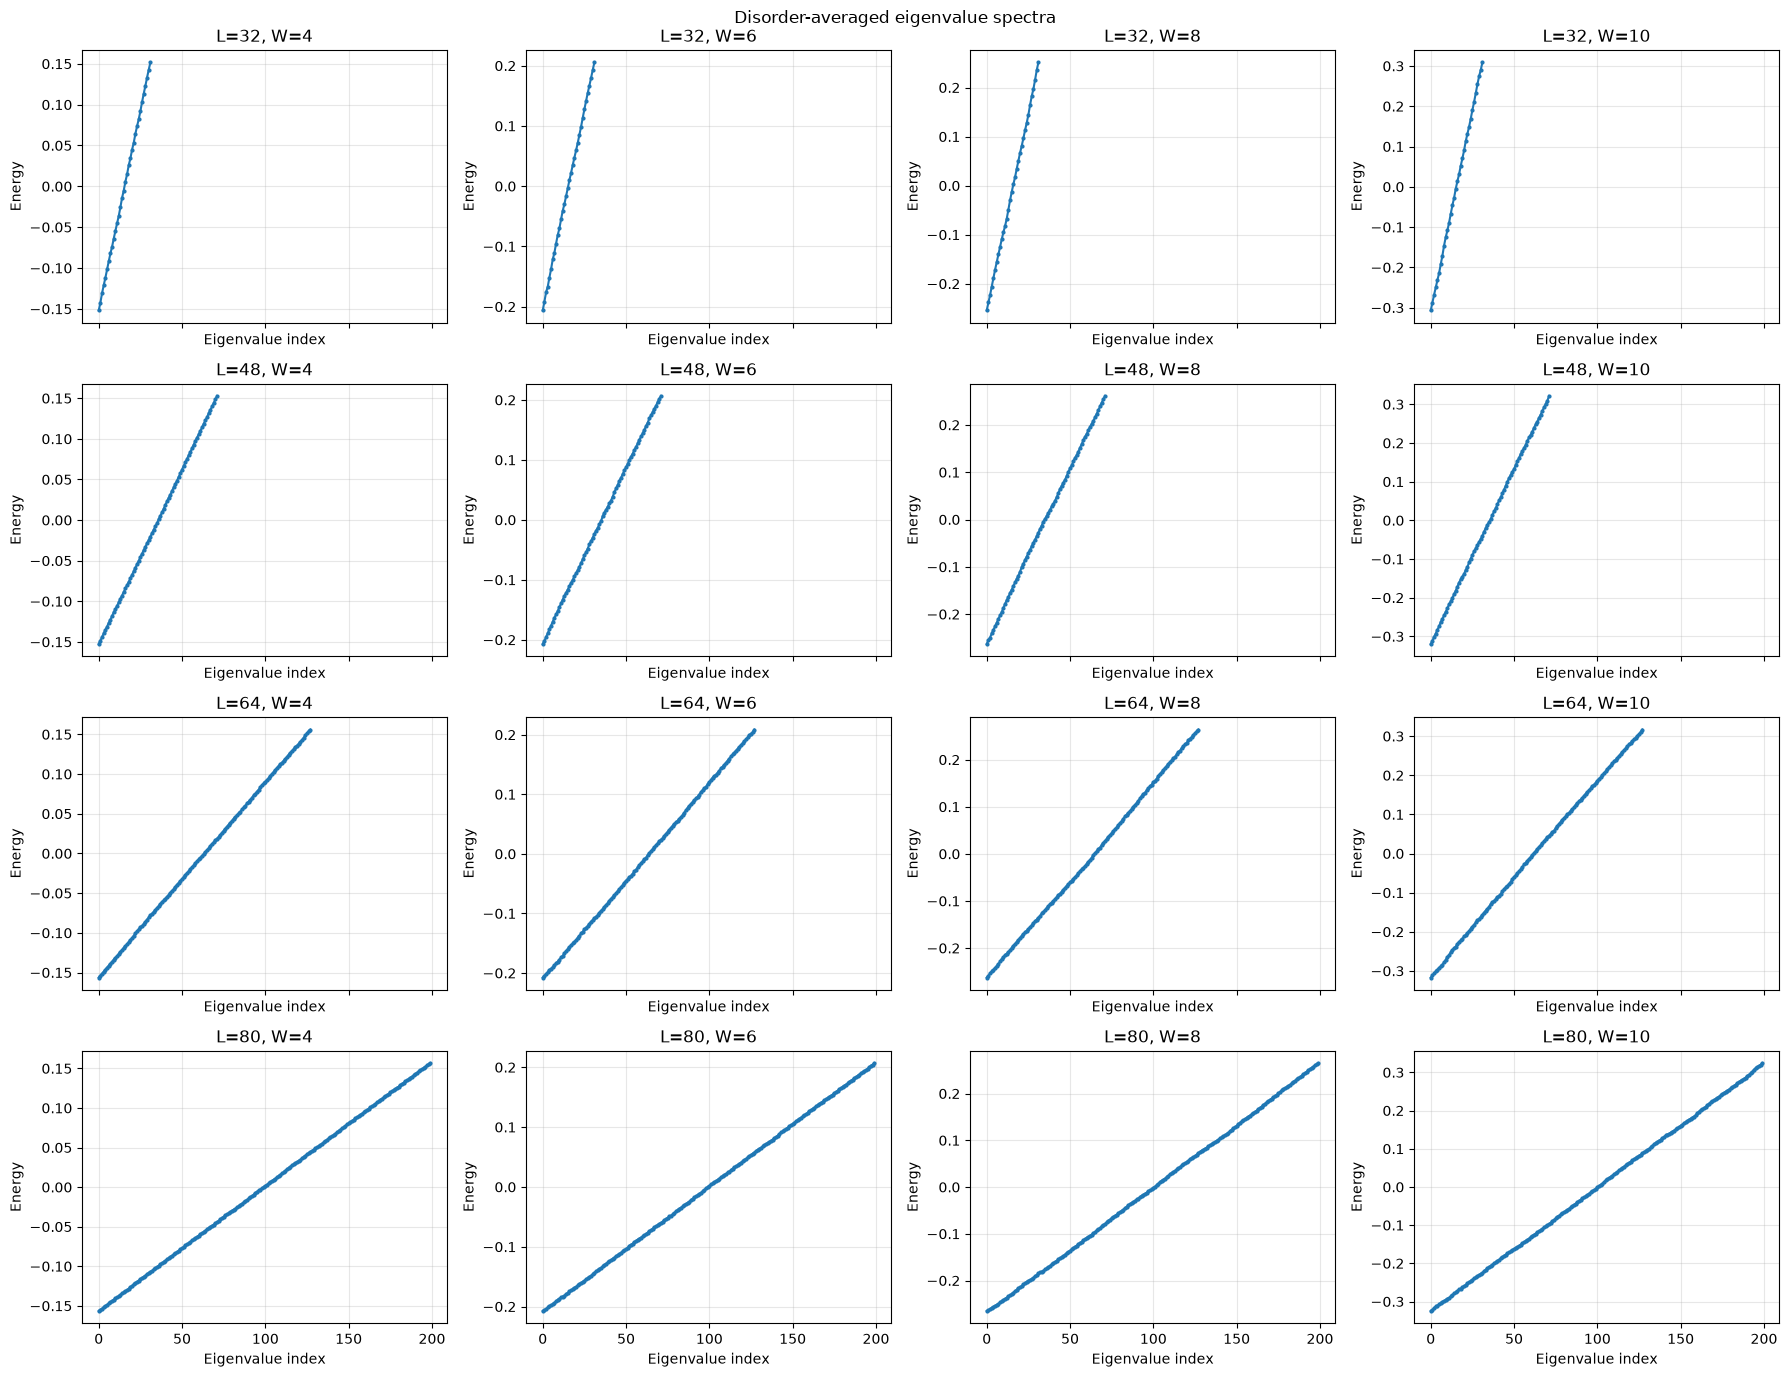

In [286]:
fig, axes = plt.subplots(len(L_list), len(W_list), figsize=(18, 14), sharex=True)
for i, L in enumerate(L_list):

    for j, W in enumerate(W_list):

        ax = axes[i, j]

        eigenvalues = eigenvalue_avg_results[(L, W)]

        ax.plot(np.arange(len(eigenvalues)), eigenvalues, 'o-', markersize=2)

        ax.set_title(f"L={L}, W={W}")

        ax.set_xlabel("Eigenvalue index")
        ax.set_ylabel("Energy")

        ax.grid(alpha=0.3)

plt.suptitle("Disorder-averaged eigenvalue spectra")

plt.tight_layout()
plt.show()

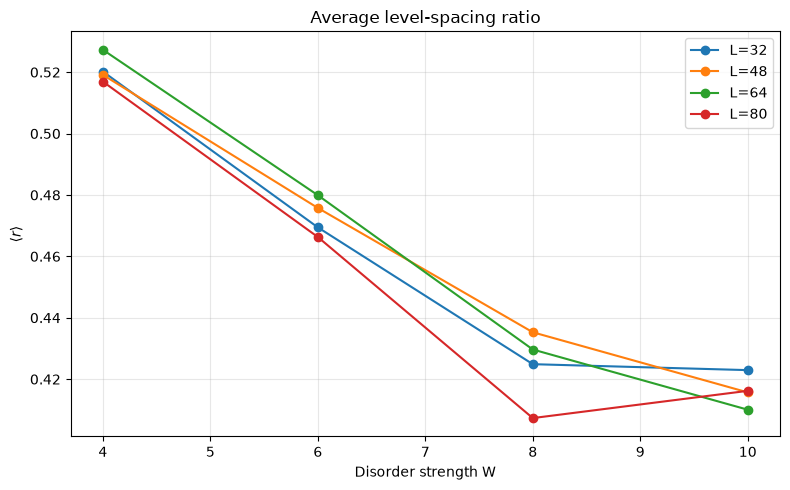

In [287]:
plt.figure(figsize=(8, 5))

for L in L_list:

    mean_r_values = [level_spacing_results[(L, W)] for W in W_list]

    plt.plot(W_list, mean_r_values, 'o-', label=f"L={L}")

plt.xlabel("Disorder strength W")
plt.ylabel(r"$\langle r\rangle$")

plt.title("Average level-spacing ratio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Plot generalized site IPR vs q

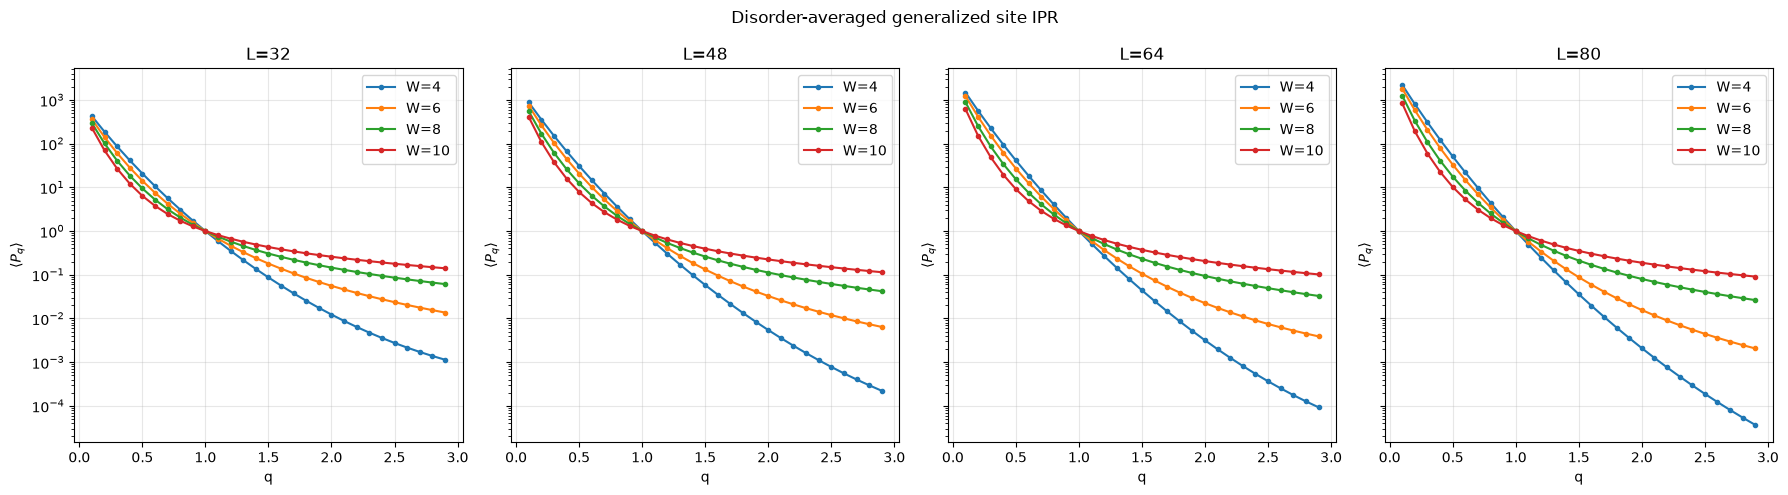

In [305]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)
for i, L in enumerate(L_list):

    ax = axes[i]
    for W in W_list:

        IPR_avg = IPR_avg_results[(L, W)]

        ax.plot(q_list, IPR_avg, 'o-', markersize=3, label=f"W={W}")

    ax.set_xlabel("q")
    ax.set_ylabel(r"$\langle P_q\rangle$")
    ax.set_title(f"L={L}")

    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Disorder-averaged generalized site IPR")

plt.tight_layout()
plt.show()

Plot generalized layer IPR vs q 

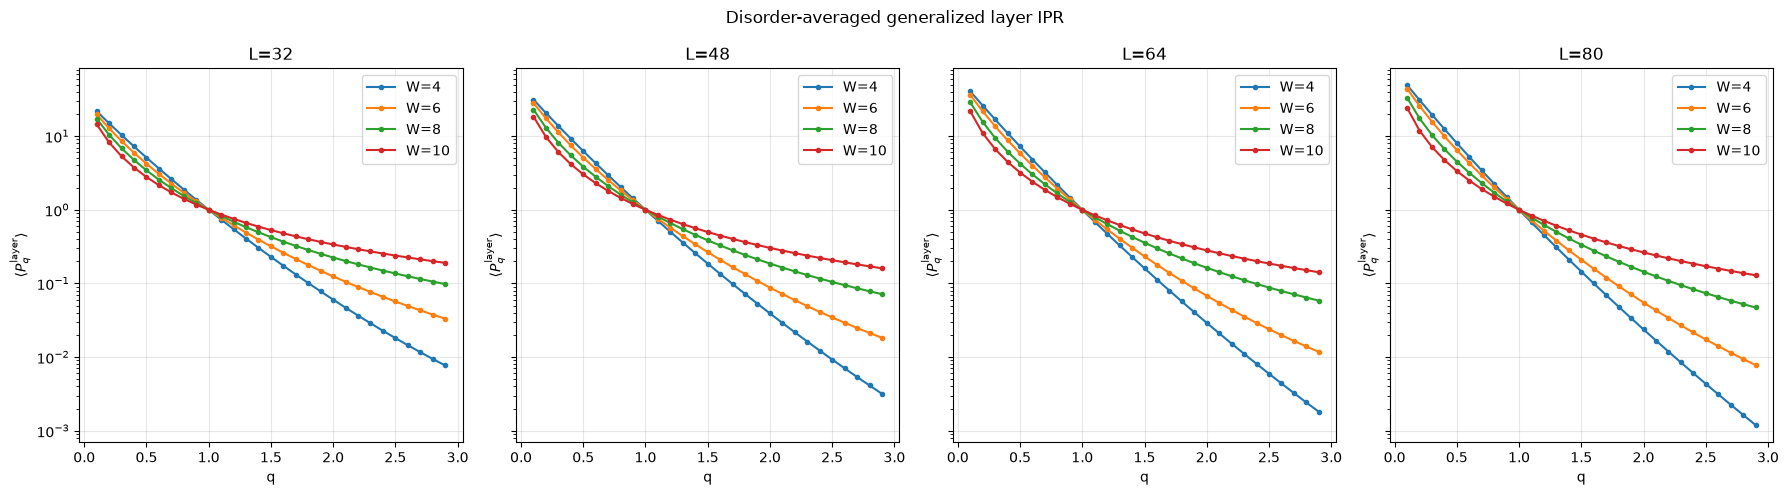

In [289]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)

for i, L in enumerate(L_list):

    ax = axes[i]

    for W in W_list:

        Layer_IPR_avg = Layer_IPR_avg_results[(L, W)]

        ax.plot(q_list, Layer_IPR_avg, 'o-', markersize=3, label=f"W={W}")

    ax.set_xlabel("q")
    ax.set_ylabel(r"$\langle P_q^{\mathrm{layer}}\rangle$")
    ax.set_title(f"L={L}")

    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Disorder-averaged generalized layer IPR")

plt.tight_layout()
plt.show()

IPR vs L for different q 

plot average layer Probability 

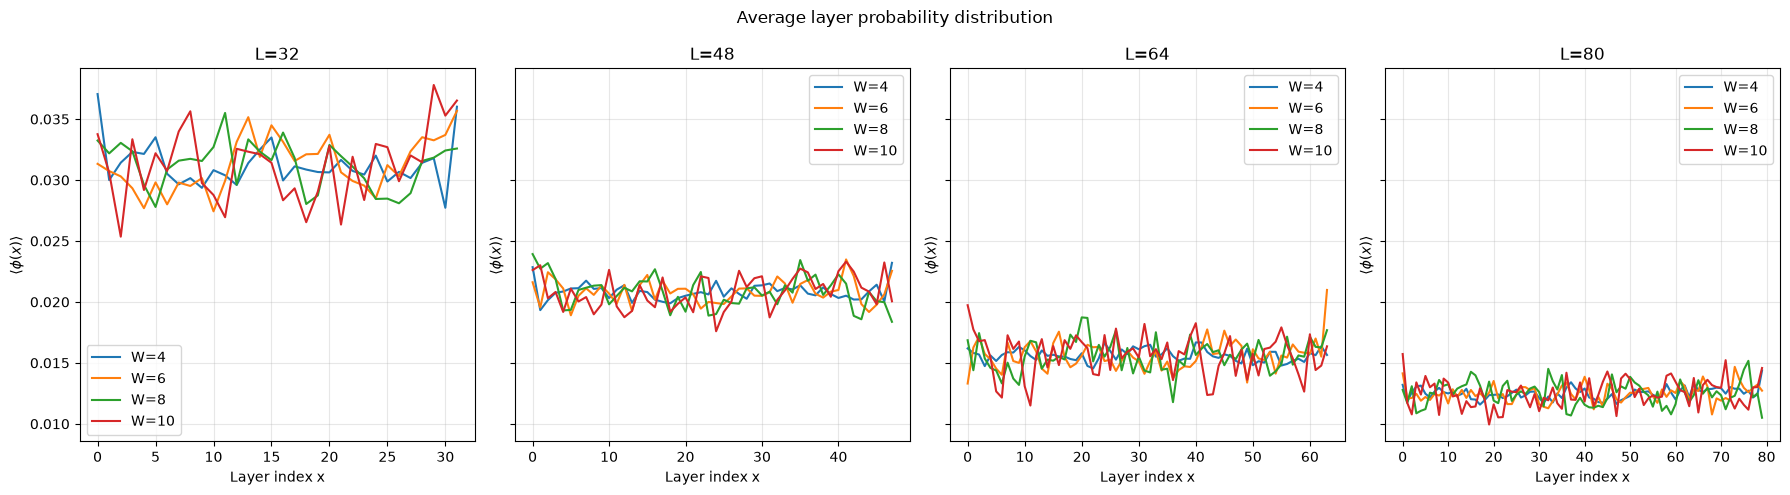

In [290]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)

for i, L in enumerate(L_list):

    ax = axes[i]

    for W in W_list:

        P_avg = layer_probability_avg_results[(L, W)]

        ax.plot(np.arange(L),P_avg,label=f"W={W}")

    ax.set_xlabel("Layer index x")
    ax.set_ylabel(r"$\langle \phi(x)\rangle$")
    ax.set_title(f"L={L}")

    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Average layer probability distribution")

plt.tight_layout()
plt.show()

In [291]:
layer_probability_avg_results[(32, 4)].shape

(32,)

Plot the Average correlation 

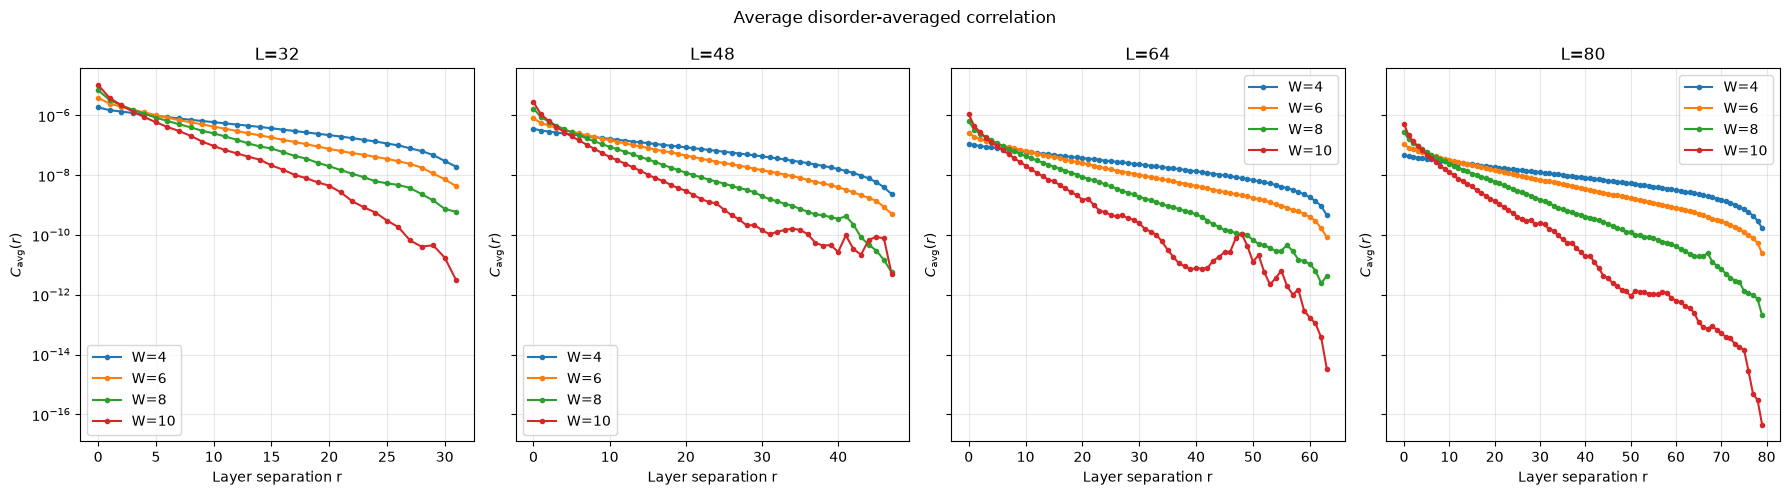

In [292]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)

for i, L in enumerate(L_list):

    ax = axes[i]

    for W in W_list:

        C_avg = C_avg_results[(L, W)]

        ax.plot(np.arange(L), C_avg, 'o-', markersize=3, label=f"W={W}")

    ax.set_xlabel("Layer separation r")
    ax.set_ylabel(r"$C_{\mathrm{avg}}(r)$")
    ax.set_title(f"L={L}")

    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Average disorder-averaged correlation")

plt.tight_layout()
plt.show()

Periodic 

Plot typical correlation 

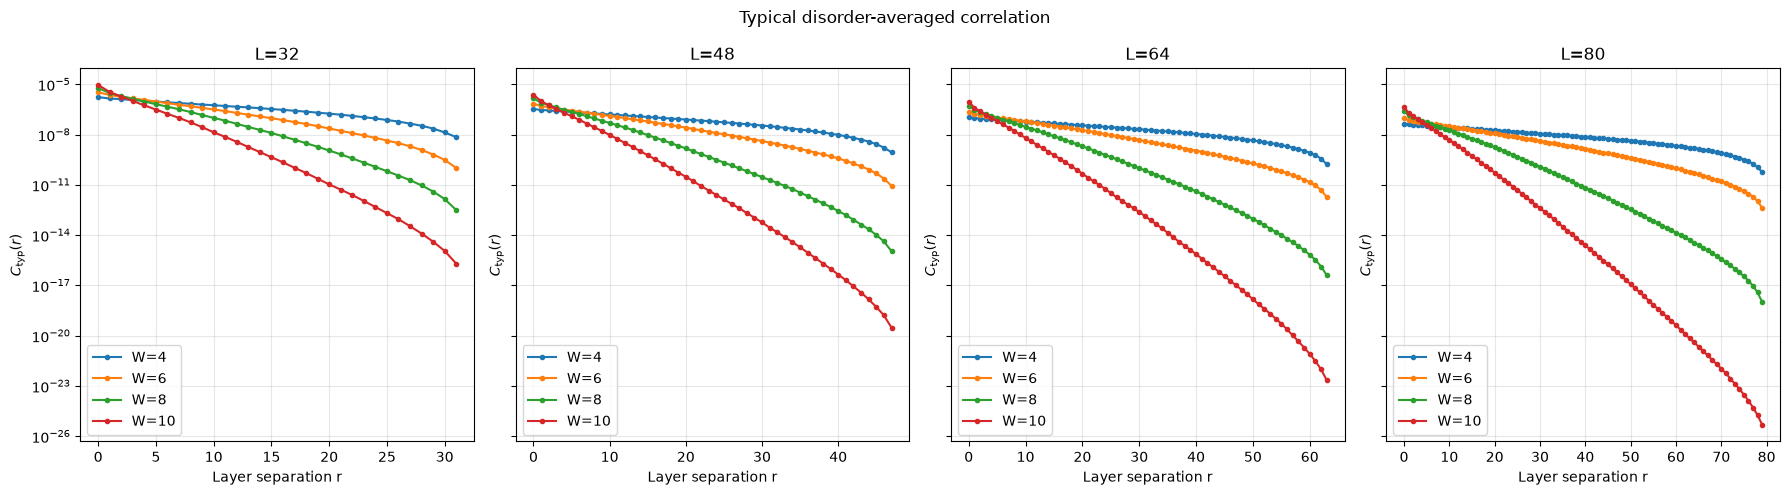

In [293]:
fig, axes = plt.subplots(1, len(L_list), figsize=(18, 5), sharey=True)

for i, L in enumerate(L_list):

    ax = axes[i]

    for W in W_list:

        C_typ = C_typ_results[(L, W)]

        # Avoid plotting exact zeros on a logarithmic scale
        positive = C_typ > 0

        ax.plot(
            np.arange(L)[positive], C_typ[positive], 'o-', markersize=3, label=f"W={W}")

    ax.set_xlabel("Layer separation r")
    ax.set_ylabel(r"$C_{\mathrm{typ}}(r)$")
    ax.set_title(f"L={L}")

    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Typical disorder-averaged correlation")

plt.tight_layout()
plt.show()

Compare Average and typical correlation 

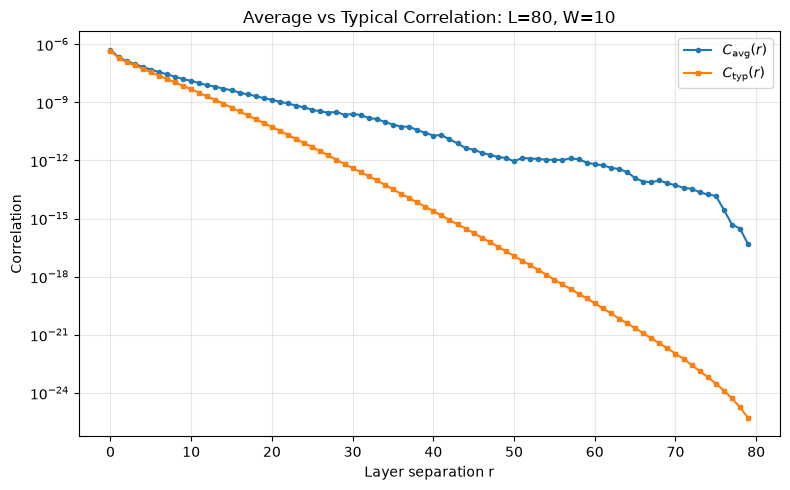

In [296]:
L = 80
W = 10

C_avg = C_avg_results[(L, W)]
C_typ = C_typ_results[(L, W)]

r = np.arange(L)

plt.figure(figsize=(8, 5))

plt.plot(r, C_avg, 'o-', markersize=3, label=r"$C_{\mathrm{avg}}(r)$")

positive = C_typ > 0

plt.plot(r[positive], C_typ[positive], 's-', markersize=3, label=r"$C_{\mathrm{typ}}(r)$")

plt.xlabel("Layer separation r")
plt.ylabel("Correlation")

plt.title(f"Average vs Typical Correlation: L={L}, W={W}")

plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [191]:
save_eigenvectors = True

eigenvector_dir = os.path.join(
    save_dir,
    "Eigenvectors"
)

os.makedirs(eigenvector_dir, exist_ok=True)



In [96]:
layer_probability1 = np.array([
    [1, 2, 3], 
    [4, 5, 6], 
    [7, 8, 9],
    [10, 11, 12],
    [13, 14, 15]
])

Lx = 5 
r = 2 

layer_probability1[:Lx-r, :]


array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [97]:
layer_probability1[r:, :]

array([[ 7,  8,  9],
       [10, 11, 12],
       [13, 14, 15]])

In [99]:
layer_probability1[:Lx-r, :] * layer_probability1[r:, :]

array([[  7,  16,  27],
       [ 40,  55,  72],
       [ 91, 112, 135]])